In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Hiển thị đầy đủ
pd.set_option('display.max_columns', None)

# Style cho biểu đồ
sns.set_theme(style="whitegrid")

# Đọc dữ liệu
sheet_id = "1B_zrNj6vaC8-Cg6ypu9Tz9uRLIPtzBBLL9yRLtVyiAY"
gid = "1073279846"  # ID của sheet/tab

url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={gid}"

df = pd.read_csv(url)

print("Kích thước dữ liệu:", df.shape)
display(df.head())

Kích thước dữ liệu: (1767, 18)


,product_id,title,authors,original_price,current_price,quantity,category,n_review,avg_rating,pages,manufacturer,cover_link,discount,discount_percent,revenue,price_segment,rating_group,page_segment
0,74021317,Cây Cam Ngọt Của Tôi,José Mauro De Vasconcelos,4.56,2.73,53075,Tiểu Thuyết,11481,5.0,244,Nhà Xuất Bản Hội Nhà Văn,https://salt.tadacdn.com/ts/product/5e/18/24/2...,0.4,40.13,"144894,75",Dưới $5,Xuất sắc (4.5 - 5.0),Sách trung bình (200-500 trang)
1,184466860,Hành Tinh Của Một Kẻ Nghĩ Nhiều,Nguyễn Đoàn Minh Thư,3.63,2.53,7929,Others,780,4.8,184,Nhà Xuất Bản Thế Giới,https://salt.tadacdn.com/ts/product/d7/99/24/1...,0.3,30.30,"20060,37",Dưới $5,Xuất sắc (4.5 - 5.0),Sách mỏng (<200 trang)
2,73787185,Những Tù Nhân Của Địa Lý,Tim Marshall,8.86,5.32,17896,Lĩnh Vực Khác,3623,4.8,430,Nhà Xuất Bản Hội Nhà Văn,https://salt.tadacdn.com/ts/product/8d/96/9e/c...,0.4,39.95,"95206,72",Từ $5 - $10,Xuất sắc (4.5 - 5.0),Sách trung bình (200-500 trang)
3,52789367,Nhà Giả Kim (Tái Bản 2020),Paulo Coelho,3.33,2.00,24668,Tác Phẩm Kinh Điển,5131,5.0,228,Nhà Xuất Bản Hà Nội,https://salt.tadacdn.com/ts/product/45/3b/fc/a...,0.4,39.94,49336,Dưới $5,Xuất sắc (4.5 - 5.0),Sách trung bình (200-500 trang)
4,147920903,Một Thoáng Ta Rực Rỡ Ở Nhân Gian,Unknown,5.70,3.42,10000,Tiểu Thuyết,1636,4.8,304,Nhà Xuất Bản Hội Nhà Văn,https://salt.tadacdn.com/ts/product/2f/b5/4e/a...,0.4,40.00,34200,Dưới $5,Xuất sắc (4.5 - 5.0),Sách trung bình (200-500 trang)


In [ ]:
df.describe()

,product_id,original_price,current_price,quantity,n_review,avg_rating,pages,discount,discount_percent
count,1.767000e+03,1767.000000,1767.000000,1767.000000,1767.000000,1767.000000,1767.000000,1767.000000,1767.000000
mean,1.161866e+08,6.692586,4.861330,2805.490662,328.848896,4.596491,347.202603,0.272264,27.244584
std,7.248487e+07,5.367041,4.298247,16796.190782,730.947525,1.129788,180.553555,0.135319,13.521009
min,3.353370e+05,0.000000,0.000000,1.000000,0.000000,0.000000,10.000000,0.000000,0.000000
25%,5.274105e+07,3.760000,2.530000,180.500000,16.000000,4.800000,220.000000,0.200000,19.965000
50%,1.149380e+08,5.440000,3.750000,608.000000,75.000000,4.800000,332.000000,0.300000,30.000000
75%,1.925865e+08,7.970000,5.760000,2376.000000,304.500000,5.000000,456.000000,0.370000,37.040000
max,2.079098e+08,65.400000,50.630000,671121.000000,11481.000000,5.000000,2004.000000,0.800000,80.150000


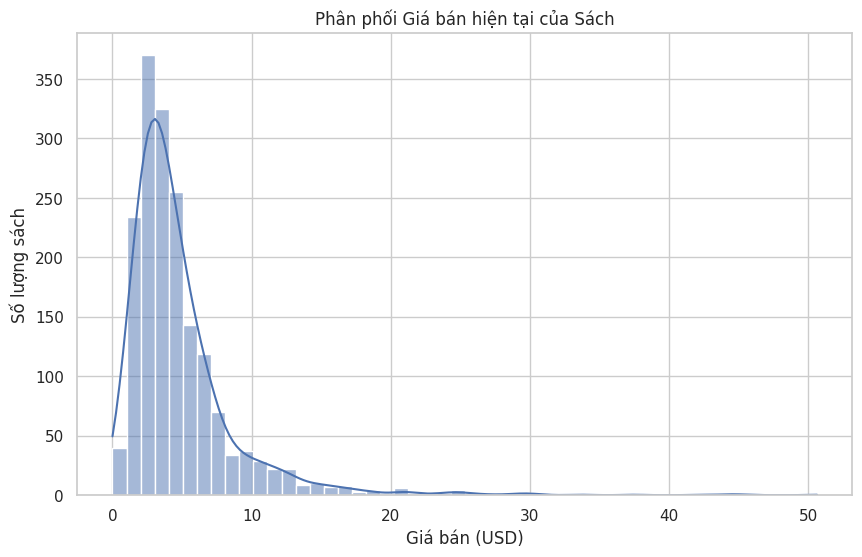

In [ ]:
# Histogram của current_price

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='current_price',
    bins=50,
    kde=True
)

plt.title('Phân phối Giá bán hiện tại của Sách')
plt.xlabel('Giá bán (USD)')
plt.ylabel('Số lượng sách')

plt.show()

In [ ]:
### Mục đích

# Biểu đồ được sử dụng để kiểm tra phân phối giá bán hiện tại của các đầu sách TADA và xác định mức giá phổ biến cũng như sự xuất hiện của các giá trị cực đoan.

### Quan sát

#- Phần lớn sách có giá bán tương đối thấp.
#- Median của `current_price` khoảng 3.75 USD trong khi maximum lên tới khoảng 50.63 USD.
#- Phân phối có độ lệch phải mạnh.
#- Một số ít sách có giá cao hơn đáng kể so với phần lớn dataset.

### Giả thuyết/Kết luận ban đầu

#Danh mục sách TADA trong dataset hiện tại tập trung chủ yếu ở phân khúc giá thấp.
#Vì vậy, phân khúc giá có thể là một yếu tố quan trọng cần kiểm tra khi phân tích số lượng bán và doanh thu.

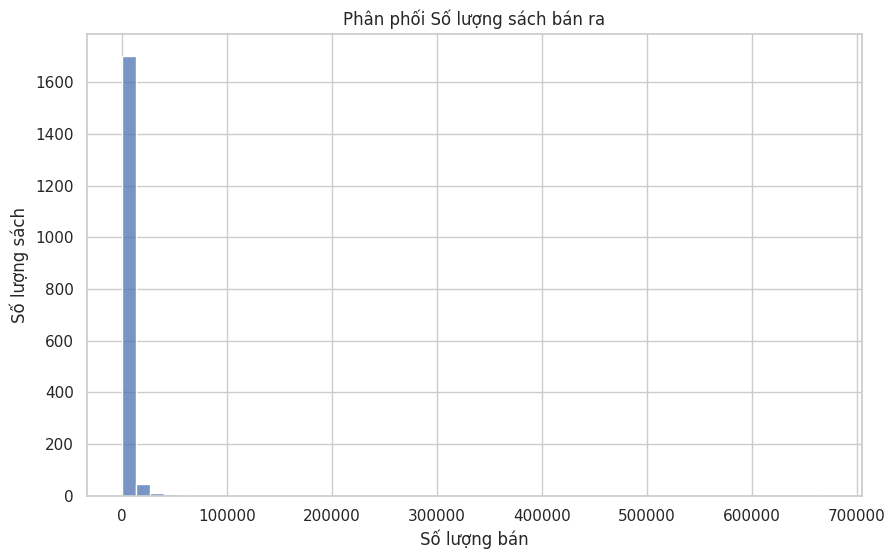

In [ ]:
# Phân phối Quantity

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='quantity',
    bins=50
)

plt.title('Phân phối Số lượng sách bán ra')
plt.xlabel('Số lượng bán')
plt.ylabel('Số lượng sách')

plt.show()

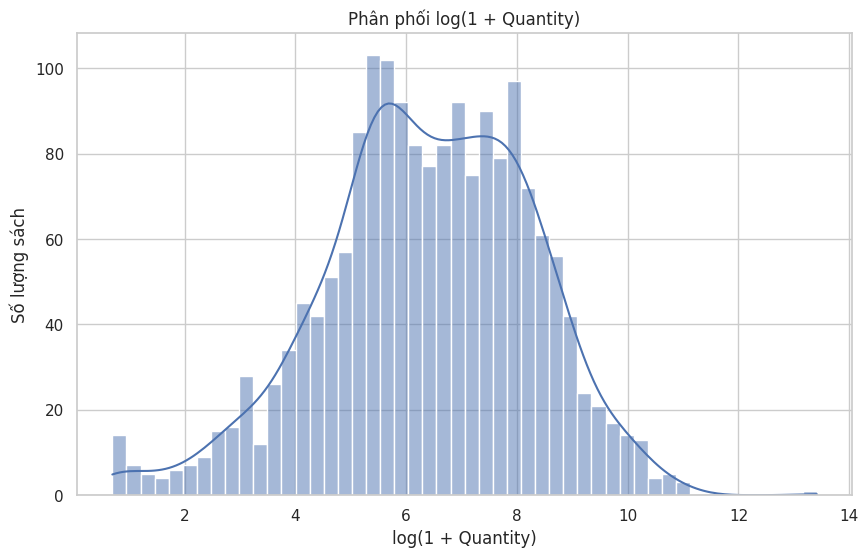

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    np.log1p(df['quantity']),
    bins=50,
    kde=True
)

plt.title('Phân phối log(1 + Quantity)')
plt.xlabel('log(1 + Quantity)')
plt.ylabel('Số lượng sách')

plt.show()

### Mục đích

Kiểm tra phân phối số lượng sách bán ra và xác định mức độ tập trung cũng như các giá trị bất thường.

### Quan sát

- `quantity` có phân phối lệch phải rất mạnh.
- Median chỉ khoảng 608 sách nhưng maximum lên tới 671,121.
- Điều này cho thấy một số ít đầu sách có lượng bán vượt trội so với phần còn lại.
- Mean lớn hơn nhiều so với median do ảnh hưởng của các giá trị cực lớn.

### Giả thuyết/Kết luận ban đầu

Doanh số sách không phân bố đồng đều giữa các đầu sách. Một số ít sản phẩm có thể đóng góp tỷ trọng lớn vào tổng lượng bán và doanh thu. Đây là nhóm cần được phân tích riêng trong các bước tiếp theo.

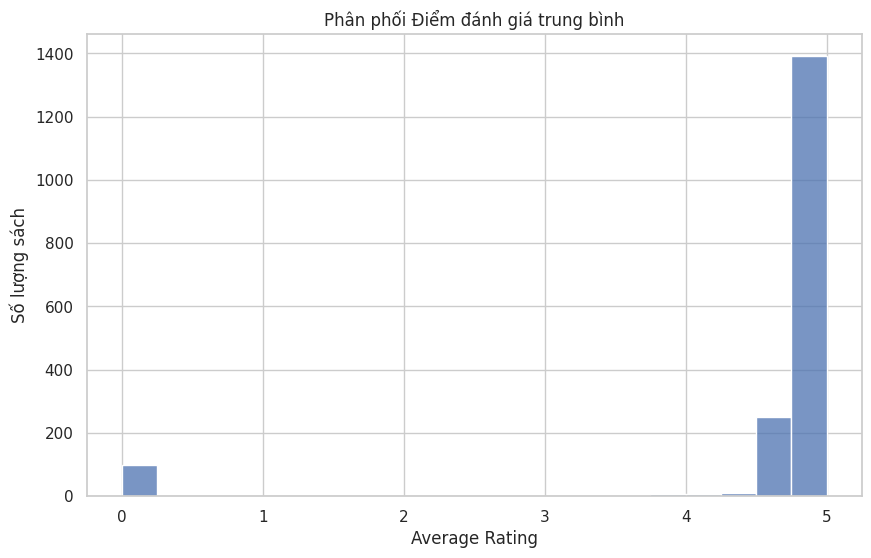

In [ ]:
# Phân phối rating
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='avg_rating',
    bins=20,
    discrete=False
)

plt.title('Phân phối Điểm đánh giá trung bình')
plt.xlabel('Average Rating')
plt.ylabel('Số lượng sách')

plt.show()

### Mục đích

Kiểm tra phân phối điểm đánh giá của các đầu sách.

### Quan sát

- Điểm đánh giá trung bình của dataset khoảng 4.60.
- Median khoảng 4.80.
- Phần lớn sách có rating cao.
- Có 98 sách thuộc nhóm "Chưa có đánh giá".
- Nhóm rating từ 4.5–5.0 chiếm phần lớn dataset.

### Giả thuyết/Kết luận ban đầu

Dataset có xu hướng tập trung vào các sách được đánh giá cao. Do đó, rating có thể không phải là biến đủ mạnh để giải thích sự khác biệt về quantity nếu phần lớn sách đều có rating cao.

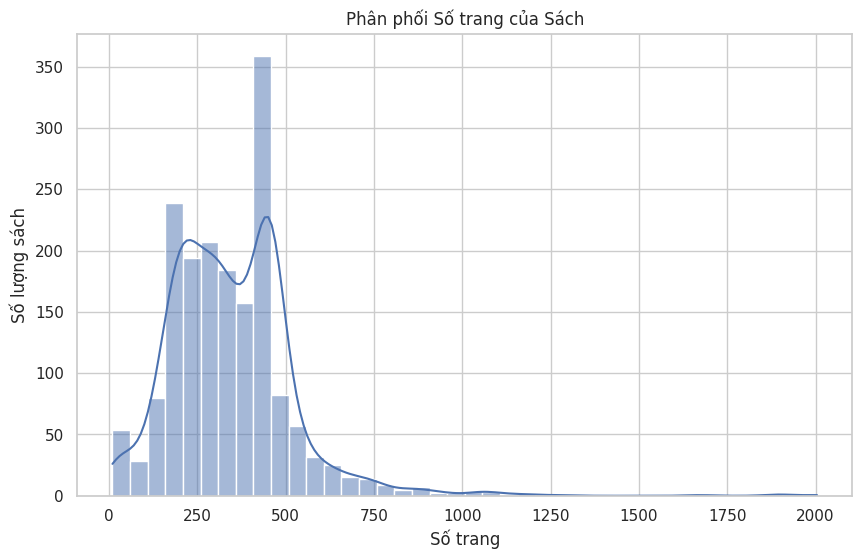

In [ ]:
# Phân phối số trang sách
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='pages',
    bins=40,
    kde=True
)

plt.title('Phân phối Số trang của Sách')
plt.xlabel('Số trang')
plt.ylabel('Số lượng sách')

plt.show()

### Mục đích

Phân tích độ dài của các đầu sách dựa trên số trang.

### Quan sát

- Số trang trung bình khoảng 347 trang.
- Median khoảng 332 trang.
- Phần lớn sách nằm trong vùng vài trăm trang.
- Một số sách có số trang rất lớn, lên tới hơn 2,000 trang.

### Giả thuyết/Kết luận ban đầu

Số trang có thể có mối quan hệ với giá bán, vì sách có nhiều trang hơn có thể cần chi phí sản xuất cao hơn. Mối quan hệ này sẽ được kiểm tra bằng scatter plot ở phần đa biến.

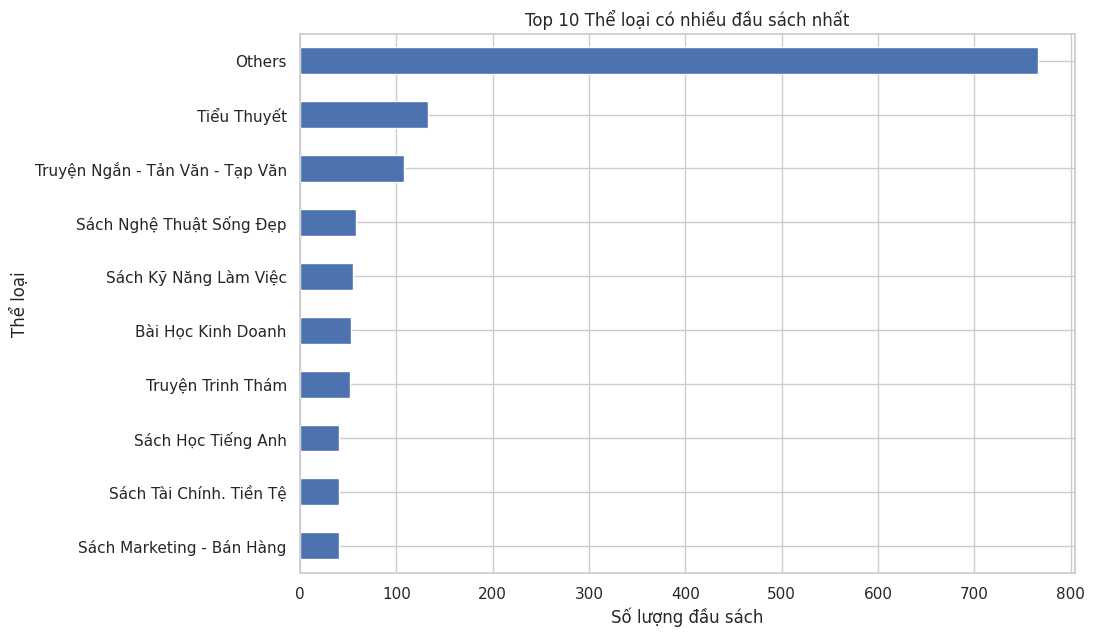

In [ ]:
# Top 10 category
category_counts = (
    df['category']
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 7))

category_counts.plot(kind='barh')

plt.title('Top 10 Thể loại có nhiều đầu sách nhất')
plt.xlabel('Số lượng đầu sách')
plt.ylabel('Thể loại')

plt.show()

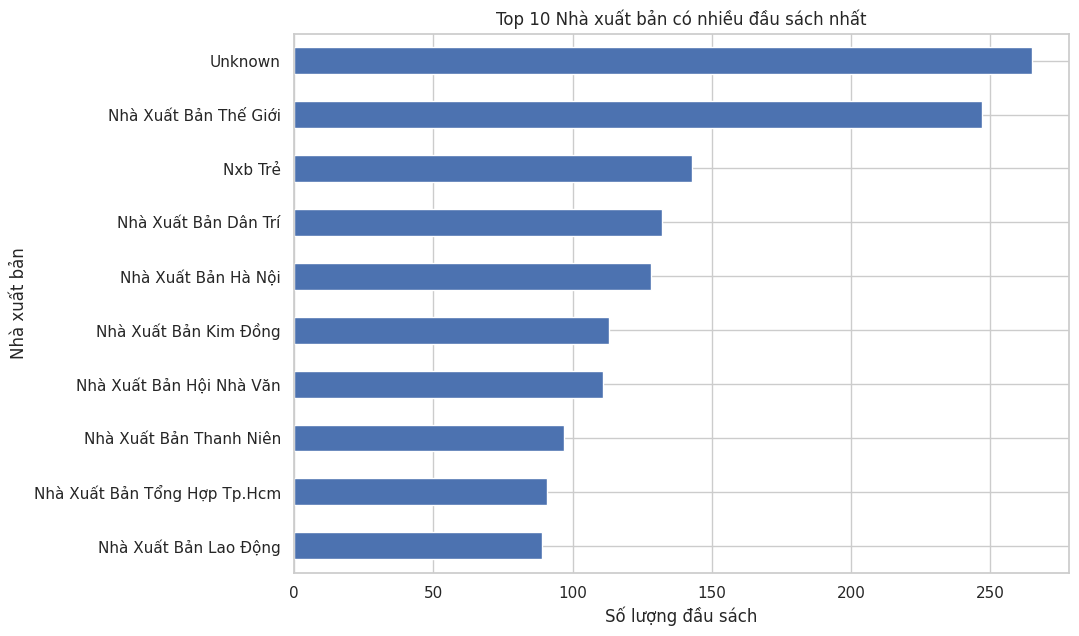

In [ ]:
# Top manufacturer
manufacturer_counts = (
    df['manufacturer']
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 7))

manufacturer_counts.plot(kind='barh')

plt.title('Top 10 Nhà xuất bản có nhiều đầu sách nhất')
plt.xlabel('Số lượng đầu sách')
plt.ylabel('Nhà xuất bản')

plt.show()

### Mục đích

Xác định các nhà xuất bản xuất hiện nhiều nhất trong dataset.

### Quan sát

- "Unknown" có 265 đầu sách.
- Nhà Xuất Bản Thế Giới có 247 đầu sách.
- NXB Trẻ có 143 đầu sách.
- Nhà Xuất Bản Dân Trí có 132 đầu sách.
- Nhà Xuất Bản Hà Nội có 128 đầu sách.

### Giả thuyết/Kết luận ban đầu

Một số nhà xuất bản có số lượng đầu sách lớn hơn đáng kể. Tuy nhiên, số lượng đầu sách không đồng nghĩa với hiệu quả kinh doanh cao, do đó cần tiếp tục so sánh quantity và revenue theo manufacturer.

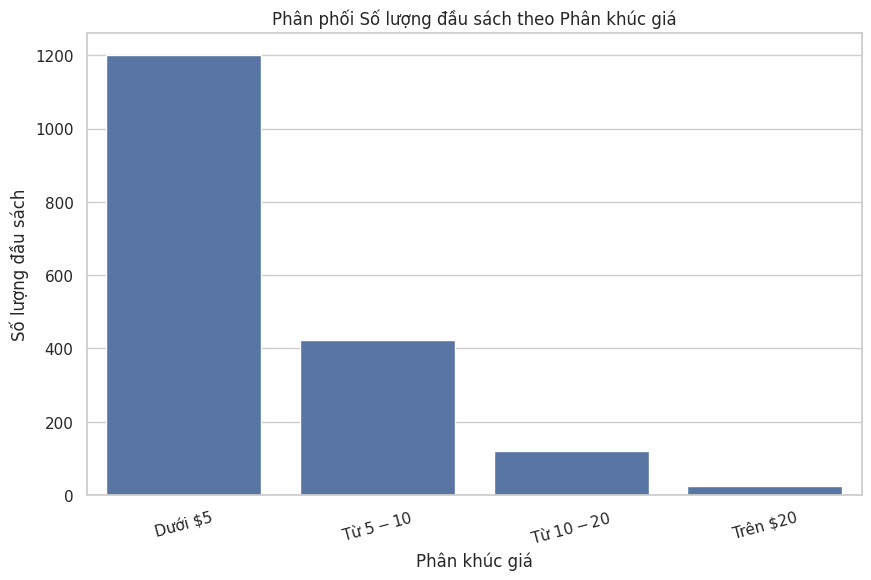

In [ ]:
# Price Segment
price_order = [
    'Dưới $5',
    'Từ $5 - $10',
    'Từ $10 - $20',
    'Trên $20'
]

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='price_segment',
    order=price_order
)

plt.title('Phân phối Số lượng đầu sách theo Phân khúc giá')
plt.xlabel('Phân khúc giá')
plt.ylabel('Số lượng đầu sách')

plt.xticks(rotation=15)

plt.show()

### Mục đích

Kiểm tra cơ cấu danh mục sách theo các phân khúc giá.

### Quan sát

- "Dưới $5" có 1,201 đầu sách, chiếm phần lớn dataset.
- "Từ $5 - $10" có 422 đầu sách.
- "Từ $10 - $20" có 119 đầu sách.
- "Trên $20" chỉ có 25 đầu sách.

### Giả thuyết/Kết luận ban đầu

Danh mục TADA trong dataset tập trung mạnh ở phân khúc dưới $5. Cần kiểm tra tiếp liệu phân khúc giá thấp có đồng thời tạo ra lượng bán cao hơn hay chỉ đơn giản là có nhiều đầu sách hơn.

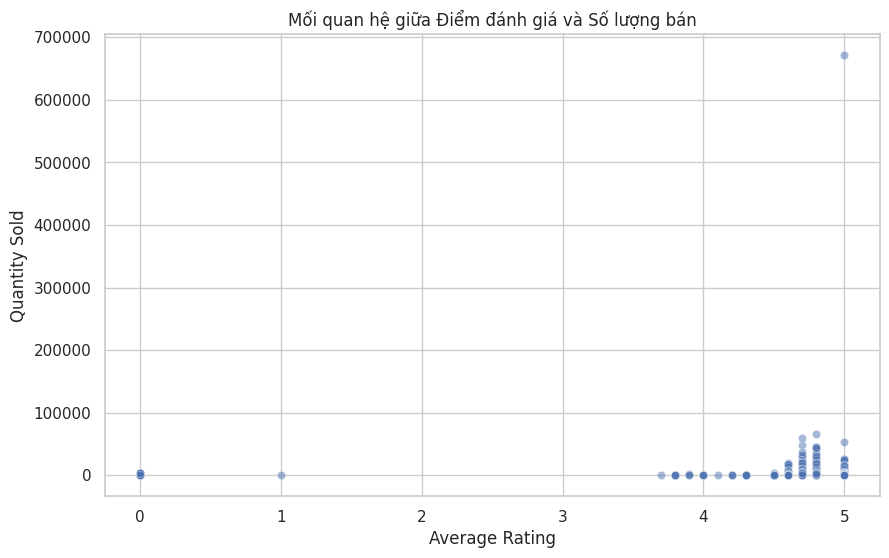

In [ ]:
# Scatter Rating vs Quantity

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='avg_rating',
    y='quantity',
    alpha=0.5
)

plt.title('Mối quan hệ giữa Điểm đánh giá và Số lượng bán')
plt.xlabel('Average Rating')
plt.ylabel('Quantity Sold')

plt.show()

### Mục đích

Kiểm tra giả thuyết liệu sách có điểm đánh giá cao hơn có xu hướng bán được nhiều hơn hay không.

### Quan sát

- Các điểm dữ liệu phân tán khá rộng.
- Có một số outlier có quantity rất lớn.
- Không quan sát thấy xu hướng tuyến tính rõ ràng giữa rating và quantity.
- Pearson correlation giữa `avg_rating` và `quantity` chỉ khoảng 0.02.

### Giả thuyết/Kết luận ban đầu

Trong dataset hiện tại, điểm đánh giá trung bình không cho thấy mối quan hệ tuyến tính đáng kể với số lượng bán. Do đó, rating đơn lẻ có thể không phải yếu tố chính giải thích sự khác biệt về doanh số.

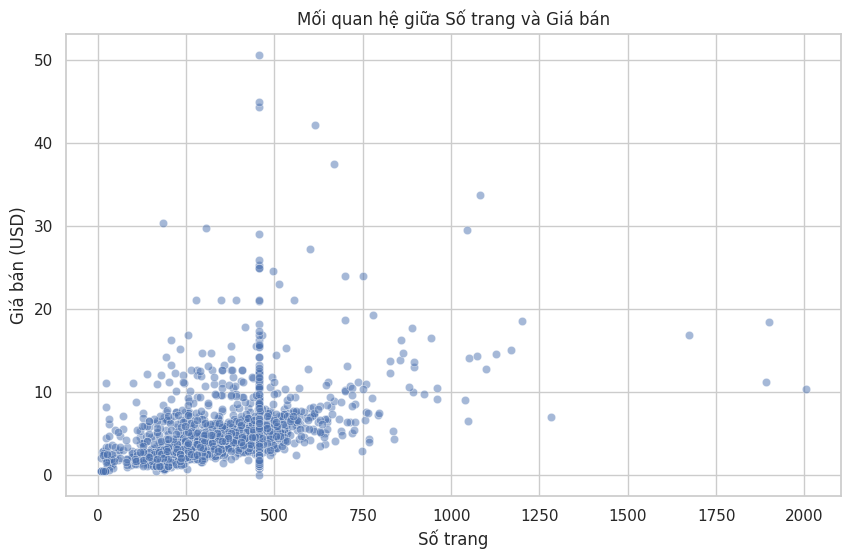

In [ ]:
# Pages vs Current Price

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='pages',
    y='current_price',
    alpha=0.5
)

plt.title('Mối quan hệ giữa Số trang và Giá bán')
plt.xlabel('Số trang')
plt.ylabel('Giá bán (USD)')

plt.show()

### Mục đích

Kiểm tra giả thuyết liệu sách có nhiều trang hơn có xu hướng có giá bán cao hơn hay không.

### Quan sát

- Có xu hướng tăng giữa số trang và giá bán.
- Pearson correlation giữa `pages` và `current_price` khoảng 0.42.
- Tuy nhiên, dữ liệu vẫn phân tán khá lớn và tồn tại một số outlier.

### Giả thuyết/Kết luận ban đầu

Số trang có mối quan hệ dương ở mức vừa phải với giá bán. Sách nhiều trang có xu hướng có giá cao hơn, nhưng số trang không phải yếu tố duy nhất quyết định giá.

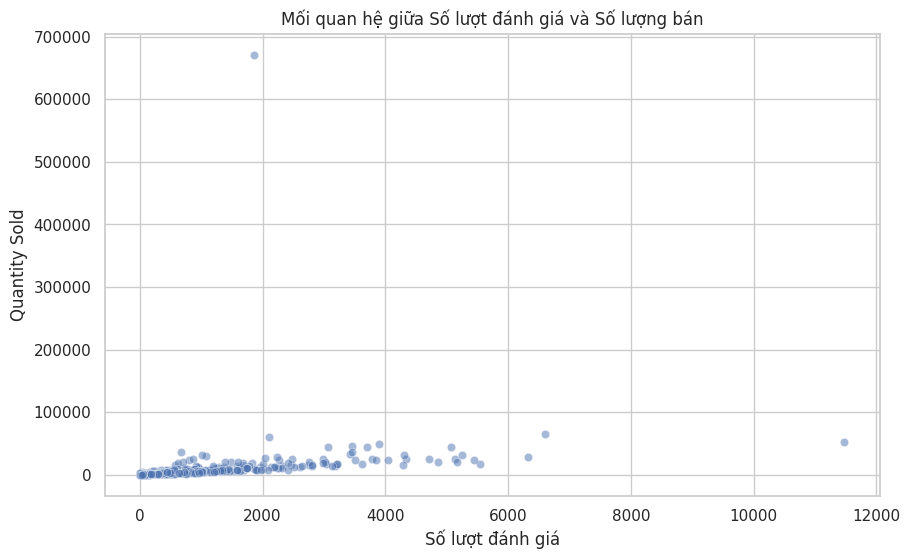

In [ ]:
# n_review vs Quantity
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='n_review',
    y='quantity',
    alpha=0.5
)

plt.title('Mối quan hệ giữa Số lượt đánh giá và Số lượng bán')
plt.xlabel('Số lượt đánh giá')
plt.ylabel('Quantity Sold')

plt.show()

### Mục đích

Kiểm tra liệu những cuốn sách có nhiều lượt đánh giá có xu hướng bán được nhiều hơn hay không.

### Quan sát

- Có xu hướng dương giữa `n_review` và `quantity`.
- Pearson correlation khoảng 0.32.
- Một số sách có cả số lượt đánh giá và quantity rất cao.

### Giả thuyết/Kết luận ban đầu

Số lượt đánh giá có mối quan hệ dương ở mức vừa phải với số lượng bán. Có thể tồn tại mối liên hệ giữa mức độ tương tác của khách hàng và hiệu quả bán hàng.

Tuy nhiên, correlation không chứng minh rằng review trực tiếp gây ra doanh số cao.

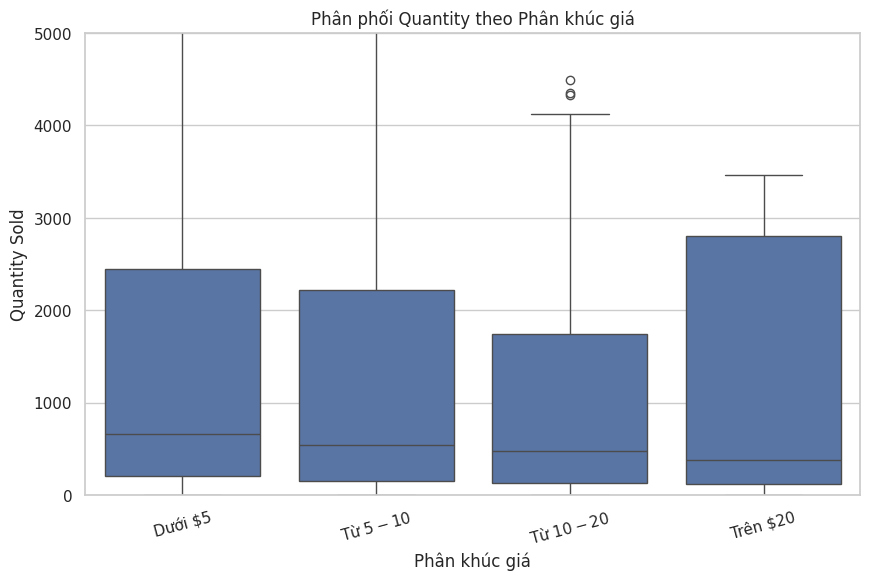

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='price_segment',
    y='quantity',
    order=price_order
)

plt.title('Phân phối Quantity theo Phân khúc giá')
plt.xlabel('Phân khúc giá')
plt.ylabel('Quantity Sold')

plt.ylim(0, 5000)

plt.xticks(rotation=15)

plt.show()

### Mục đích

So sánh phân phối số lượng bán ra giữa các phân khúc giá.

### Quan sát

- Phân khúc "Dưới $5" có median quantity khoảng 660.
- "Từ $5 - $10" có median khoảng 547.
- "Từ $10 - $20" có median khoảng 476.
- "Trên $20" có median khoảng 382.
- Phân khúc giá thấp có median quantity cao hơn trong dataset hiện tại.

### Giả thuyết/Kết luận ban đầu

Trong dataset TADA, sách thuộc phân khúc giá thấp có xu hướng có quantity bán cao hơn. Đây là một tín hiệu cho thấy giá bán có thể liên quan đến sức bán, tuy nhiên cần kiểm soát thêm các yếu tố khác như category và độ phổ biến.

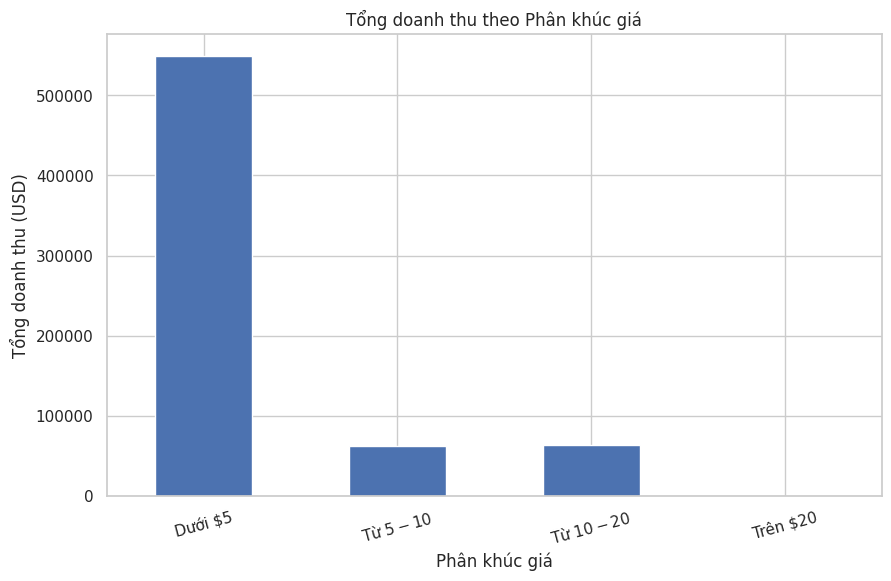

In [ ]:
# Revenue theo Price Segment
df['revenue'] = pd.to_numeric(df['revenue'], errors='coerce')
revenue_by_price = (
    df.groupby('price_segment')['revenue']
      .sum()
      .reindex(price_order)
)

plt.figure(figsize=(10, 6))

revenue_by_price.plot(kind='bar')

plt.title('Tổng doanh thu theo Phân khúc giá')
plt.xlabel('Phân khúc giá')
plt.ylabel('Tổng doanh thu (USD)')

plt.xticks(rotation=15)

plt.show()

### Mục đích

So sánh tổng doanh thu giữa các phân khúc giá để xác định phân khúc nào đóng góp nhiều nhất vào doanh thu.

### Quan sát

Phân khúc "Dưới $5" có số lượng đầu sách lớn nhất và đồng thời tạo ra tổng quantity rất lớn. Do đó, đây là phân khúc cần được xem xét kỹ khi đánh giá hiệu quả kinh doanh.

### Giả thuyết/Kết luận ban đầu

Phân khúc giá thấp có thể đóng vai trò quan trọng trong doanh thu và số lượng bán của TADA. Tuy nhiên, cần phân biệt giữa "do có nhiều đầu sách" và "mỗi đầu sách thực sự hiệu quả", vì vậy nên phân tích thêm doanh thu/đầu sách hoặc quantity/đầu sách.

# Tổng hợp kết quả EDA

## 1. Phân phối dữ liệu

- Giá bán (`current_price`) có phân phối lệch phải, phần lớn sách có giá thấp.
- Số lượng bán (`quantity`) có độ lệch phải rất mạnh, với một số đầu sách có lượng bán vượt trội.
- Số lượt đánh giá (`n_review`) cũng lệch phải.
- Điểm đánh giá (`avg_rating`) tập trung cao, phần lớn sách có rating từ 4.5 trở lên.
- Số trang (`pages`) có phân phối lệch phải nhẹ đến vừa.

## 2. Cơ cấu danh mục

- Dataset tập trung mạnh vào phân khúc giá dưới $5.
- Một số category như Tiểu Thuyết và Truyện Ngắn - Tản Văn - Tạp Văn có số lượng đầu sách tương đối lớn.
- Một số nhà xuất bản có số lượng đầu sách vượt trội so với các nhà xuất bản khác.

## 3. Mối quan hệ giữa các biến

- `original_price` và `current_price` có tương quan rất mạnh.
- `pages` có tương quan dương vừa phải với giá bán.
- `n_review` có tương quan dương mức vừa với `quantity`.
- `avg_rating` gần như không có tương quan tuyến tính với `quantity`.
- `discount_percent` cũng không có tương quan tuyến tính mạnh với `quantity`.
- `quantity` và `revenue` có tương quan rất mạnh, điều này hợp lý vì revenue được tính dựa trên current_price × quantity.

## 4. Các giả thuyết cho phân tích tiếp theo

### Giả thuyết 1
Sách ở phân khúc giá thấp có xu hướng bán được nhiều hơn.

### Giả thuyết 2
Số lượt đánh giá cao có liên hệ với số lượng bán cao hơn.

### Giả thuyết 3
Số trang có thể là một yếu tố liên quan đến giá bán.

### Giả thuyết 4
Rating trung bình không phải yếu tố duy nhất hoặc yếu tố chính giải thích quantity trong dataset hiện tại.

### Giả thuyết 5
Một số ít đầu sách có thể đóng góp phần lớn quantity và revenue, do phân phối doanh số có độ lệch phải rất lớn.